In [1]:
# Check whether Google Colab has given us a GPU
import torch

if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
else:
    print("No GPU found. Go to Runtime -> Change runtime type -> T4 GPU")

GPU available: Tesla T4


In [2]:
# Install the free libraries needed for training
%pip install -q transformers datasets accelerate sentencepiece

In [1]:
# Check the installed library versions
import transformers
import datasets
import accelerate

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)

Transformers: 5.20.1
Datasets: 4.8.5
Accelerate: 1.15.0


In [2]:
# Upload train.jsonl and test.jsonl from the laptop
from pathlib import Path

TRAIN_FILE = Path("/content/train.jsonl")
TEST_FILE = Path("/content/test.jsonl")

# Only ask for the upload if the files are not already in Colab
if not (TRAIN_FILE.exists() and TEST_FILE.exists()):
    from google.colab import files
    print("Please choose train.jsonl and test.jsonl")
    files.upload()

print("Training file found:", TRAIN_FILE.exists())
print("Testing file found:", TEST_FILE.exists())

Please choose train.jsonl and test.jsonl


Saving test.jsonl to test.jsonl
Saving train.jsonl to train.jsonl
Training file found: True
Testing file found: True


In [3]:
# Read the uploaded files and turn them into training datasets
import json
from datasets import Dataset

def read_jsonl(path):
    """Read a .jsonl file and keep only valid question/answer rows."""
    rows = []
    with open(path, "r", encoding="utf-8") as file:
        for line in file:
            record = json.loads(line)
            question = record.get("question", "").strip()
            answer = record.get("answer", "").strip()
            if question and answer:
                rows.append({"question": question, "answer": answer})
    return rows

train_rows = read_jsonl(TRAIN_FILE)
test_rows = read_jsonl(TEST_FILE)

train_dataset = Dataset.from_list(train_rows)
test_dataset = Dataset.from_list(test_rows)

print("Training examples:", len(train_dataset))
print("Testing examples:", len(test_dataset))
print("\nSample:", train_dataset[0])

Training examples: 52804
Testing examples: 5868

Sample: {'question': 'what place?', 'answer': 'the usual place. in front of the treasure house.'}


In [4]:
# Load the pretrained model and its tokenizer
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "google/flan-t5-small"

# Words we put in front of every message (the chatbot app must use the same words)
PROMPT_PREFIX = "Reply to this message: "

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

print("Model loaded:", MODEL_NAME)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Device:", device)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model loaded: google/flan-t5-small
Parameters: 76,961,152
Device: cuda


In [5]:
# Test messages we will use before AND after training
TEST_MESSAGES = [
    "hi, how are you?",
    "what are you doing this weekend?",
    "can you help me find a hotel?",
    "i'm feeling tired today.",
    "do you like playing football?",
]

def chat(message, seed=42):
    """Get one reply from the model."""
    torch.manual_seed(seed)          # same seed = repeatable answers
    model.eval()                     # switch the model to "answering" mode

    # Turn the message into tokens (same prefix as training)
    inputs = tokenizer(
        PROMPT_PREFIX + message.lower().strip(),
        return_tensors="pt",
        max_length=64,
        truncation=True,
    ).to(device)

    # Let the model write a reply
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=48,       # reply length limit
            do_sample=True,          # pick words with a little randomness
            top_p=0.9,
            temperature=0.8,
            no_repeat_ngram_size=3,  # avoid repeating the same phrase
        )

    # Turn the tokens back into text
    return tokenizer.decode(output[0], skip_special_tokens=True)

# Save the answers so we can compare them after training
answers_before = {message: chat(message) for message in TEST_MESSAGES}

for message, answer in answers_before.items():
    print("Q:", message)
    print("A:", answer)
    print("-" * 40)

Q: hi, how are you?
A: Hi, what are you doing?
----------------------------------------
Q: what are you doing this weekend?
A: Hi, what are you doing this weekend?
----------------------------------------
Q: can you help me find a hotel?
A: Sure, what is the price range of the hotel?
----------------------------------------
Q: i'm feeling tired today.
A: I need to get some rest.
----------------------------------------
Q: do you like playing football?
A: I like to play football.
----------------------------------------


In [6]:
# Maximum number of tokens for messages and replies
MAX_INPUT_LENGTH = 64
MAX_TARGET_LENGTH = 64

def preprocess(batch):
    """Turn a batch of question/answer text into tokens."""
    # Input: prefix + message
    inputs = [PROMPT_PREFIX + question for question in batch["question"]]
    model_inputs = tokenizer(inputs, max_length=MAX_INPUT_LENGTH, truncation=True)

    # Label: the correct reply
    labels = tokenizer(text_target=batch["answer"], max_length=MAX_TARGET_LENGTH, truncation=True)
    model_inputs["labels"] = labels["input_ids"]

    return model_inputs

# Tokenize both datasets (batched=True makes it much faster)
tokenized_train = train_dataset.map(preprocess, batched=True, remove_columns=train_dataset.column_names)
tokenized_test = test_dataset.map(preprocess, batched=True, remove_columns=test_dataset.column_names)

print("Tokenized training rows:", len(tokenized_train))
print("Tokenized testing rows:", len(tokenized_test))
print("Columns:", tokenized_train.column_names)

Map:   0%|          | 0/52804 [00:00<?, ? examples/s]

Map:   0%|          | 0/5868 [00:00<?, ? examples/s]

Tokenized training rows: 52804
Tokenized testing rows: 5868
Columns: ['input_ids', 'attention_mask', 'labels']


In [7]:
# Prepare batches and check that the loss is a normal number
import math
from transformers import DataCollatorForSeq2Seq

# The collator groups examples into batches and pads them to the same length
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, padding=True)

# Take 8 examples and calculate the loss once
sample_batch = data_collator([tokenized_train[i] for i in range(8)])
sample_batch = {key: value.to(device) for key, value in sample_batch.items()}

with torch.no_grad():
    start_loss = model(**sample_batch).loss.item()

print("Loss before training:", round(start_loss, 3))
assert math.isfinite(start_loss), "Loss is nan! Restart the session and run all cells again."

Loss before training: 2.968


In [8]:
# Training settings and the trainer
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, TrainerCallback

class StopIfLossBreaks(TrainerCallback):
    """Stop training right away if the loss becomes nan, inf, or 0.0."""
    def on_log(self, args, state, control, logs=None, **kwargs):
        loss = (logs or {}).get("loss")
        if loss is not None and (not math.isfinite(loss) or loss == 0.0):
            print(f"Loss became {loss}. Stopping training.")
            control.should_training_stop = True

training_args = Seq2SeqTrainingArguments(
    output_dir="/content/minichatgpt-checkpoints",
    num_train_epochs=3,                 # read all the data 3 times
    per_device_train_batch_size=32,     # 32 examples per step
    per_device_eval_batch_size=64,
    learning_rate=3e-4,                 # how big each learning step is
    weight_decay=0.01,                  # helps avoid memorizing
    warmup_steps=200,                   # start slowly for the first 200 steps
    fp16=False,                         # IMPORTANT: fp16 caused the nan error
    bf16=False,                         # T4 GPU does not support bf16
    eval_strategy="epoch",              # test on test.jsonl after each epoch
    save_strategy="epoch",              # save a checkpoint after each epoch
    load_best_model_at_end=True,        # keep the epoch with the best test result
    metric_for_best_model="eval_loss",
    greater_is_better=False,            # lower loss is better
    save_total_limit=2,                 # keep only 2 checkpoints (saves disk space)
    logging_steps=100,                  # print the loss every 100 steps
    report_to="none",
    seed=42,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    processing_class=tokenizer,
    callbacks=[StopIfLossBreaks()],
)

print("Trainer is ready.")
print("Steps per epoch:", math.ceil(len(tokenized_train) / 32))

Trainer is ready.
Steps per epoch: 1651


In [10]:
# Start training and measure how long it takes
import time

start_time = time.time()
train_result = trainer.train()
minutes = (time.time() - start_time) / 60

print("Training finished in", round(minutes, 1), "minutes")
print("Final training loss:", round(train_result.training_loss, 4))

Epoch,Training Loss,Validation Loss
1,2.475300,2.448951
2,2.401331,2.431867
3,2.332531,2.431987


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Training finished in 17.9 minutes
Final training loss: 2.3993


In [11]:
# Check that the best model loaded correctly
final_eval = trainer.evaluate()
print("Test loss of the loaded model:", round(final_eval["eval_loss"], 4))

# The embedding layers should be shared with model.shared
print("Encoder embeddings OK:", torch.equal(model.encoder.embed_tokens.weight, model.shared.weight))
print("Decoder embeddings OK:", torch.equal(model.decoder.embed_tokens.weight, model.shared.weight))

Training Loss,Validation Loss,Epoch
2.332531,2.431867,3


Test loss of the loaded model: 2.4319
Encoder embeddings OK: True
Decoder embeddings OK: True


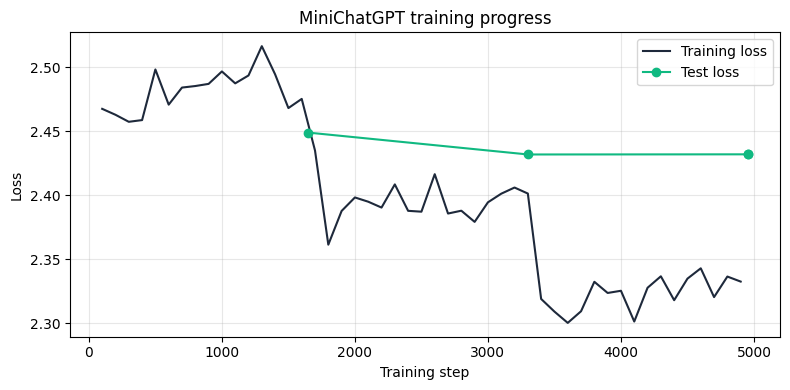

In [12]:
# Draw the training progress chart
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_points = [(h["step"], h["loss"]) for h in history if "loss" in h]
eval_points = [(h["step"], h["eval_loss"]) for h in history if "eval_loss" in h]

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_points), label="Training loss", color="#1E293B")
plt.plot(*zip(*eval_points), "o-", label="Test loss", color="#10B981")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("MiniChatGPT training progress")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/training_loss.png", dpi=150)
plt.show()

In [13]:
# Compare answers before and after training
for message in TEST_MESSAGES:
    print("Q:", message)
    print("Before training:", answers_before[message])
    print("After training: ", chat(message))
    print("-" * 60)

Q: hi, how are you?
Before training: Hi, what are you doing?
After training:  fine, thanks.
------------------------------------------------------------
Q: what are you doing this weekend?
Before training: Hi, what are you doing this weekend?
After training:  i'm going to be going to the london beach.
------------------------------------------------------------
Q: can you help me find a hotel?
Before training: Sure, what is the price range of the hotel?
After training:  sure, what type of hotel would you like?
------------------------------------------------------------
Q: i'm feeling tired today.
Before training: I need to get some rest.
After training:  don't worry, i'll be up early.
------------------------------------------------------------
Q: do you like playing football?
Before training: I like to play football.
After training:  yes, i do.
------------------------------------------------------------


In [17]:
# Try your own messages
my_messages = [
    "where do you work?",
    "what time is it?",
    "i want to buy a new phone.",
]

for message in my_messages:
    print("Q:", message)
    print("A:", chat(message))
    print("-" * 40)

Q: where do you work?
A: i work at a telecommunications company.
----------------------------------------
Q: what time is it?
A: at 10:00, it's going to be at one of the restaurants.
----------------------------------------
Q: i want to buy a new phone.
A: where are you going to get it?
----------------------------------------


In [18]:
# Save the TRAINED model, tokenizer, chart, and a training report
import json
import shutil

SAVE_DIR = Path("/content/minichatgpt-model")

trainer.save_model(str(SAVE_DIR))        # the trained model (best epoch)
tokenizer.save_pretrained(str(SAVE_DIR)) # the tokenizer (text <-> numbers)

# A short report with the most important numbers
history = trainer.state.log_history
report = {
    "base_model": MODEL_NAME,
    "prompt_prefix": PROMPT_PREFIX,
    "train_examples": len(train_dataset),
    "test_examples": len(test_dataset),
    "epochs": training_args.num_train_epochs,
    "learning_rate": training_args.learning_rate,
    "batch_size": training_args.per_device_train_batch_size,
    "loss_before_training": round(start_loss, 4),
    "final_training_loss": round(train_result.training_loss, 4),
    "final_test_loss": round(final_eval["eval_loss"], 4),
    "test_loss_per_epoch": [round(h["eval_loss"], 4) for h in history if "eval_loss" in h],
    "training_minutes": round(minutes, 1),
}
(SAVE_DIR / "training_report.json").write_text(json.dumps(report, indent=2))
shutil.copy("/content/training_loss.png", SAVE_DIR / "training_loss.png")

print(json.dumps(report, indent=2))
print("\nFiles saved:")
for file in sorted(SAVE_DIR.iterdir()):
    print(" -", file.name)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "base_model": "google/flan-t5-small",
  "prompt_prefix": "Reply to this message: ",
  "train_examples": 52804,
  "test_examples": 5868,
  "epochs": 3,
  "learning_rate": 0.0003,
  "batch_size": 32,
  "loss_before_training": 2.9679,
  "final_training_loss": 2.3993,
  "final_test_loss": 2.4319,
  "test_loss_per_epoch": [
    2.449,
    2.4319,
    2.432,
    2.4319
  ],
  "training_minutes": 17.9
}

Files saved:
 - config.json
 - generation_config.json
 - model.safetensors
 - tokenizer.json
 - tokenizer_config.json
 - training_args.bin
 - training_loss.png
 - training_report.json


In [19]:
# Load the model from the saved folder, exactly like the app will
saved_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
saved_model = AutoModelForSeq2SeqLM.from_pretrained(SAVE_DIR).to(device).eval()

inputs = saved_tokenizer(PROMPT_PREFIX + "hi, how are you?", return_tensors="pt").to(device)
with torch.no_grad():
    output = saved_model.generate(**inputs, max_new_tokens=40)

print("Saved model says:", saved_tokenizer.decode(output[0], skip_special_tokens=True))

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Saved model says: i'm fine, thanks.


In [21]:
# Zip the model folder and download it
from google.colab import files

zip_path = shutil.make_archive("/content/minichatgpt-model", "zip", SAVE_DIR)
print("ZIP created:", zip_path)

files.download(zip_path)

ZIP created: /content/minichatgpt-model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>